# 1. GET MARKET DATA


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
# Plot Cumulative Returns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import make_scorer, recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import os
from xgboost import XGBClassifier
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV


In [3]:
#data = pd.read_excel('./data/ASSURANCE VIE.xlsx', sheet_name='VIXHISTORIQUEMODEL')
usecols_l=list(range(0, 10))


In [4]:
data = pd.read_excel('data/ASSURANCE VIE.xlsx', sheet_name='VIX HISTORIQUE', skiprows=3, usecols=usecols_l)

In [5]:
data

,Loading...,Unnamed: 1,Loading....1,Unnamed: 3,Loading....2,Unnamed: 5,Loading....3,Unnamed: 7,Loading....4,Unnamed: 9
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Define the list of non-date column names
column_names = ['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y']





In [7]:
def align_df_dates(data, column_names):
# Split into 5 DataFrames
    dfs = []  # List to store the DataFrames
    for i, col_name in enumerate(column_names):
        # Select Date and corresponding column
        df = data.iloc[:, [i * 2, i * 2 + 1]].copy()  # Every second column (Date, Close)
        df.columns = ['Date', col_name]  # Rename columns
        df['Date'] = pd.to_datetime(df['Date']).dt.strftime('%Y-%m-%d')  # Convert Date column to datetime
        df = df.set_index('Date')
        df.dropna(inplace=True)  # Drop rows with missing values
        dfs.append(df)
        # Start with the first DataFrame (dfs[0]) as the base
        merged_df = dfs[0]
        
        # Iteratively merge other DataFrames based on the index
        for df in dfs[1:]:
            merged_df = merged_df.join(df, how='inner')  # Inner join to align on the index
    return merged_df

In [8]:
data= align_df_dates(data, column_names)


In [9]:
data

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y
Date,,,,,


In [10]:
data_open= pd.read_excel('data/ASSURANCE VIE.xlsx', sheet_name='VIX HISTORIQUE OPEN', skiprows=3, usecols=usecols_l)

In [11]:
open_column_names = ['SPX_OPEN', 'VIX1M_OPEN', 'VIX3M_OPEN', 'VIX6M_OPEN', 'VIX1Y_OPEN']

In [12]:
data_open=align_df_dates(data_open, open_column_names)

In [13]:
data_open

,SPX_OPEN,VIX1M_OPEN,VIX3M_OPEN,VIX6M_OPEN,VIX1Y_OPEN
Date,,,,,


In [14]:
data_merged=data.join(data_open, how='inner') 

In [15]:
data_merged

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_OPEN,VIX1M_OPEN,VIX3M_OPEN,VIX6M_OPEN,VIX1Y_OPEN
Date,,,,,,,,,,


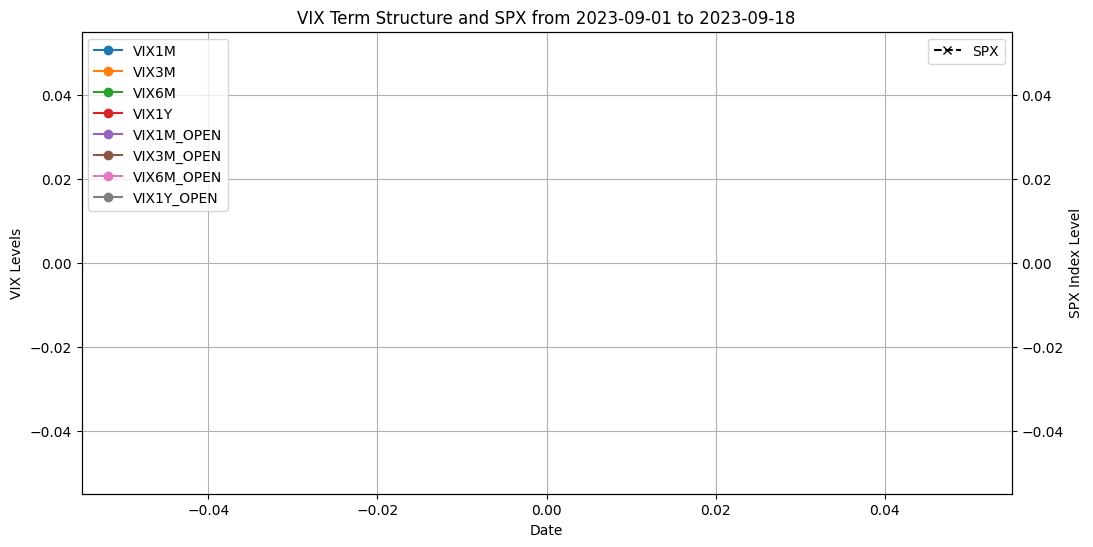

In [16]:
date_range_df = data_merged.loc['2018-09-10':'2018-10-10']  # Filter by date range

# Create the main plot for VIX columns
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot VIX columns
ax1.plot(date_range_df.index, date_range_df['VIX1M'], label='VIX1M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX3M'], label='VIX3M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX6M'], label='VIX6M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX1Y'], label='VIX1Y', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX1M_OPEN'], label='VIX1M_OPEN', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX3M_OPEN'], label='VIX3M_OPEN', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX6M_OPEN'], label='VIX6M_OPEN', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX1Y_OPEN'], label='VIX1Y_OPEN', marker='o')

# Label for the VIX axis
ax1.set_ylabel("VIX Levels")
ax1.set_xlabel("Date")
ax1.legend(loc="upper left")
ax1.grid()

# Create a second y-axis for SPX
ax2 = ax1.twinx()
ax2.plot(date_range_df.index, date_range_df['SPX'], label='SPX', color='black', linestyle='--', marker='x')
ax2.set_ylabel("SPX Index Level")
ax2.legend(loc="upper right")

# Add title
plt.title("VIX Term Structure and SPX from 2023-09-01 to 2023-09-18")

plt.savefig("VIX Crash analysis.png", dpi=300, bbox_inches="tight")


In [17]:
# Specify dates to plot the term structure for
selected_dates = ['2018-10-04', '2018-10-05', '2018-10-08', '2018-10-09', '2018-10-10']
vix_maturities = ['VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y']
maturity_labels = ['1 Month', '3 Months', '6 Months', '1 Year']

# Transpose the data for easier plotting
vix_data_transposed = data.loc[selected_dates, vix_maturities].transpose()

# Plot VIX term structure with maturities as X-axis
fig, ax = plt.subplots(figsize=(10, 6))

for date in selected_dates:
    ax.plot(maturity_labels, vix_data_transposed[date], marker='o', label=f"{date}")

# Highlight the VIX1M value for the last date
last_date = selected_dates[-1]
last_vix1m_value = vix_data_transposed.loc['VIX1M', last_date]
ax.annotate(
    "Change to backwardation",  # Annotation text
    xy=('1 Month', last_vix1m_value),  # Point being annotated
    xytext=('1 Month', last_vix1m_value + 1),  # Position of the text (numeric value)
    arrowprops=dict(facecolor='red', arrowstyle='->'),  # Arrow properties
    fontsize=10,
    color='red'
)

# Highlight the VIX3M value for the firt date: normal contango
first_date = selected_dates[0]
first_vix3m_value = vix_data_transposed.loc['VIX3M', first_date]
ax.annotate(
    "Normal Contango structure",  # Annotation text
    xy=('3 Months', first_vix3m_value),  # Point being annotated
    xytext=('3 Months', first_vix3m_value-1 ),  # Adjust upward for text placement
    arrowprops=dict(facecolor='red', arrowstyle='->'),  # Arrow properties
    fontsize=10,
    color='blue'
)


# Customize plot
ax.set_xlabel("VIX Maturities")
ax.set_ylabel("VIX Levels")
ax.set_title("VIX Term Structure Across Selected Dates")
ax.legend(title="Dates")
ax.grid()

# Save and show the plot
plt.savefig("./results/VIX_Term_Structure_Maturities.png", dpi=300, bbox_inches="tight")
plt.show()


KeyError: "None of [Index(['2018-10-04', '2018-10-05', '2018-10-08', '2018-10-09', '2018-10-10'], dtype='object', name='Date')] are in the [index]"

# 2. VIX MOVE IDENTIFICATION — RANDOM FOREST


In [ ]:
vix_data= data_merged.copy()
CRASH_DAYS=5

In [ ]:
# Calculate slopes (differences) between VIX maturities
vix_data['Slope_1M_3M'] = vix_data['VIX1M_OPEN'] - vix_data['VIX3M_OPEN']
vix_data['Slope_3M_6M'] = vix_data['VIX3M_OPEN'] - vix_data['VIX6M_OPEN']
vix_data['Slope_6M_1Y'] = vix_data['VIX6M_OPEN'] - vix_data['VIX1Y_OPEN']



In [ ]:
# Calculate the change as the difference between today's open and the previous day's close
vix_data['SPX_Change'] = vix_data['SPX__OPEN'] - vix_data['SPX'].shift(1)
vix_data['VIX1M_Change'] = vix_data['VIX1M_OPEN'] - vix_data['VIX1M'].shift(CRASH_DAYS)
vix_data['VIX3M_Change'] = vix_data['VIX3M_OPEN'] - vix_data['VIX3M'].shift(CRASH_DAYS)
vix_data['VIX6M_Change'] = vix_data['VIX6M_OPEN'] - vix_data['VIX6M'].shift(CRASH_DAYS)
vix_data['VIX1Y_Change'] = vix_data['VIX1Y_OPEN'] - vix_data['VIX1Y'].shift(CRASH_DAYS)



In [ ]:
# Calculate the same-day change for SPX and VIX indices
vix_data['SPX_Same_Day_Change'] = vix_data['SPX'] - vix_data['SPX__OPEN']
vix_data['VIX1M_Same_Day_Change'] = vix_data['VIX1M'] - vix_data['VIX1M_OPEN']
vix_data['VIX3M_Same_Day_Change'] = vix_data['VIX3M'] - vix_data['VIX3M_OPEN']
vix_data['VIX6M_Same_Day_Change'] = vix_data['VIX6M'] - vix_data['VIX6M_OPEN']
vix_data['VIX1Y_Same_Day_Change'] = vix_data['VIX1Y'] - vix_data['VIX1Y_OPEN']


In [ ]:
vix_data

In [ ]:
# Calculate the 75th percentile (upper quartile) for each relevant column
slope_1m_3m_threshold = vix_data['Slope_1M_3M'].abs().quantile(0.75)
slope_3m_6m_threshold = vix_data['Slope_3M_6M'].abs().quantile(0.75)
slope_6m_1y_threshold = vix_data['Slope_6M_1Y'].abs().quantile(0.75)

change_1m_threshold = vix_data['VIX1M_Change'].abs().quantile(0.75)
change_3m_threshold = vix_data['VIX3M_Change'].abs().quantile(0.75)
change_6m_threshold = vix_data['VIX6M_Change'].abs().quantile(0.75)
change_1y_threshold = vix_data['VIX6M_Change'].abs().quantile(0.75)

# Create the target variable `VIX_Significant_Change` using the calculated thresholds
vix_data['VIX_Significant_Change'] = (
    (vix_data['Slope_1M_3M'].abs() > slope_1m_3m_threshold) |
    (vix_data['Slope_3M_6M'].abs() > slope_3m_6m_threshold) |
    (vix_data['Slope_6M_1Y'].abs() > slope_6m_1y_threshold) |
    (vix_data['VIX1M_Change'].abs() > change_1m_threshold) |
    (vix_data['VIX3M_Change'].abs() > change_3m_threshold) |
    (vix_data['VIX6M_Change'].abs() > change_6m_threshold) |
    (vix_data['VIX6M_Change'].abs() > change_1y_threshold)
).astype(int)


In [ ]:
vix_data['VIX_Significant_Change_next'] = vix_data['VIX_Significant_Change']

In [ ]:
vix_data.dropna(inplace=True)

In [ ]:
vix_significant_change_sum = vix_data['VIX_Significant_Change'].sum()
print(vix_significant_change_sum)

In [ ]:
# Define feature set and target
X = vix_data[['Slope_1M_3M', 'Slope_3M_6M', 'Slope_6M_1Y', 'VIX1M_Change', 'VIX3M_Change', 'VIX6M_Change', 'VIX1Y_Change']]
y = vix_data['VIX_Significant_Change_next']

In [ ]:
split_point = int(len(X) * 0.8)

# Split the data<
X_train = X.iloc[:split_point]  # First 80% for training
X_test = X.iloc[split_point:]   # Last 20% for testing
y_train= y.iloc[:split_point]  # First 80% for training
y_test=y.iloc[split_point:]   # Last 20% for testing

In [ ]:
# Initialize and train the model
stage1_model = RandomForestClassifier(random_state=42)
stage1_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = stage1_model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


# 3. MODEL FEATURING


In [ ]:
# Use the Stage 1 model to make predictions on the entire dataset
vix_data['VIX_Shift_Prediction'] = stage1_model.predict(vix_data[['Slope_1M_3M', 'Slope_3M_6M', 'Slope_6M_1Y', 
                                                                  'VIX1M_Change', 'VIX3M_Change', 'VIX6M_Change', 'VIX1Y_Change']])


In [ ]:
# Create lagged features of `VIX_Shift_Prediction` and any other relevant features
vix_data['VIX_Shift_Prediction_Lag1'] = vix_data['VIX_Shift_Prediction'].shift(1)
vix_data['VIX_Shift_Prediction_Lag5'] = vix_data['VIX_Shift_Prediction'].shift(5)

vix_data['VIX_Shift_Prediction_Lag2'] = vix_data['VIX_Shift_Prediction'].shift(2)
vix_data['VIX_Shift_Prediction_Lag3'] = vix_data['VIX_Shift_Prediction'].shift(3)
vix_data['VIX_Shift_Prediction_Lag4'] = vix_data['VIX_Shift_Prediction'].shift(4)

In [ ]:
# Example crash flag based on a 5% drop over 5 days
CRASH_FLAG=-0.02


crash_label=f"Crash {CRASH_DAYS} Days"
vix_data['SPX_Change'] = vix_data['SPX'].pct_change(periods=CRASH_DAYS)
vix_data['crash_Flag'] = (vix_data['SPX_Change'] <= CRASH_FLAG).astype(int)


In [ ]:
vix_data[['SPX','SPX_Change']].head(10)

In [ ]:
crash_label

In [ ]:
# Shift the target variable 'crash_Flag' to represent the next day's crash
vix_data['Crash_Flag_Next_Day'] = vix_data['crash_Flag']






In [ ]:
# Drop rows where the next day's crash flag is NaN (e.g., the last row)
vix_data.dropna(subset=['Crash_Flag_Next_Day'], inplace=True)

In [ ]:
vix_data.to_excel("./data/vix.xlsx", index=True)

In [ ]:
# Plot the SPX time series
plt.figure(figsize=(12, 6))
plt.plot(vix_data.index, vix_data['VIX3M'], label='VIX3M', color='blue', alpha=0.7)

# Highlight dates where crash_1M is 1
crash_dates = vix_data[vix_data['crash_Flag'] == 1]
plt.scatter(crash_dates.index, vix_data.loc[crash_dates.index, 'VIX3M'], color='red', label=crash_label, marker='x', s=100)

# Customize plot
plt.xlabel('Date')
plt.ylabel('SPX Value')
plt.title(f"SPX Time Series with Crash Flags set to {CRASH_FLAG:.2f}%")
plt.legend()
plt.grid(True)
plt.savefig("./results/SPX historical.png", dpi=300, bbox_inches="tight")

In [ ]:
crash_ratio= round(vix_data['crash_Flag'].sum()/len(vix_data)*100,2)
print(f"Pourcentage of crashes using the crash flag {CRASH_FLAG:.2f}%: {crash_ratio:.2f}%")

In [ ]:
#vix_data['SPX_pct_change'] = vix_data['SPX'].pct_change()

In [ ]:
vix_data.columns

In [ ]:
# List of items to remove
drop_columns = [ 'SPX__OPEN','SPX','crash_Flag','SPX_Change','Crash_Flag_Next_Day','VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y','SPX_Same_Day_Change',
       'VIX1M_Same_Day_Change', 'VIX3M_Same_Day_Change',
       'VIX6M_Same_Day_Change', 'VIX1Y_Same_Day_Change',]
#drop_columns = [ 'crash_Flag','Crash_Flag_Next_Day']
# Filter the list
feature_columns = [item for item in vix_data.columns if item not in drop_columns]

# 4. MODEL TRAINING — XGBOOST


In [ ]:
vix_data

In [ ]:
feature_columns

In [ ]:
# Define features and target for Stage 2
X_stage2 = vix_data[feature_columns]
y_stage2 = vix_data['Crash_Flag_Next_Day']

# Drop rows with NaN values from lagged features
X_stage2 = X_stage2.dropna()
y_stage2 = y_stage2[X_stage2.index]



In [ ]:
# Define the split point for 80-20
split_point = int(len(X_stage2) * 0.8)

# Split the data
X_train_stage2 = X_stage2.iloc[:split_point]  # First 80% for training
X_test_stage2 = X_stage2.iloc[split_point:]   # Last 20% for testing
y_train_stage2= y_stage2.iloc[:split_point]  # First 80% for training
y_test_stage2=y_stage2.iloc[split_point:]   # Last 20% for testing

# Display split sizes
print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")
y_benchmark = data['SPX'].iloc[split_point:]

In [ ]:
# Train the model
# Calculate class imbalance ratio
imbalance_ratio = len(y_train_stage2[y_train_stage2 == 0]) / len(y_train_stage2[y_train_stage2 == 1])

# Adjust the model with scale_pos_weight
stage2_model = XGBClassifier(random_state=42, scale_pos_weight=imbalance_ratio)
stage2_model.fit(X_train_stage2, y_train_stage2)

# Evaluate the model
y_pred_stage2 = stage2_model.predict(X_test_stage2)
print("Accuracy:", accuracy_score(y_test_stage2, y_pred_stage2))
print("Classification Report:\n", classification_report(y_test_stage2, y_pred_stage2))


In [ ]:
# Calculate the confusion matrix
conf_matrix = confusion_matrix(y_test_stage2, y_pred_stage2)

# Normalize the confusion matrix
conf_matrix_normalized = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

# Plot the normalized confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_normalized * 100, annot=True, fmt='.2f', cmap='Blues', xticklabels=['Non-crash', 'Crash'], yticklabels=['Non-crash', 'Crash'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix in Percentage')

# Save the figure
plt.savefig("./results/confusion_matrix_percentage.png", dpi=300, bbox_inches="tight")  # Save with high resolution and tight bounding box
#plt.show()



In [ ]:
# Get predicted probabilities for the "crash" class (usually the second column of predict_proba output)
proba_crash = stage2_model.predict_proba(X_test_stage2)[:, 1]

# Create a DataFrame for easier plotting
results = pd.DataFrame({
    'Date': X_test_stage2.index,            # Assuming 'Date' is the index
    'Crash_Probability': proba_crash,       # Predicted probability of crash
    'Actual_Crash': y_test_stage2           # Actual crash labels
})


# Filter the data to include only the dates where a crash actually occurred
crash_dates = results[results['Actual_Crash'] == 1]

# Plot the predicted crash probabilities on actual crash dates
plt.figure(figsize=(12, 6))
plt.scatter(crash_dates['Date'], crash_dates['Crash_Probability'], color='red')
plt.xlabel('Date')
plt.ylabel('Predicted Probability of Crash')
plt.title('Predicted Crash Probability on Actual Crash Dates')
plt.legend()
#plt.show()
plt.savefig("./results/Predictions.png", dpi=300, bbox_inches="tight")  # Save with high resolution and tight bounding box


In [ ]:
tscv = TimeSeriesSplit(n_splits=5)
scores = cross_val_score(stage2_model, X_stage2, y_stage2, cv=tscv, scoring='accuracy')
print("TimeSeriesSplit Cross-Validation Accuracy Scores:", scores)
print("Mean CV Accuracy:", scores.mean())

In [ ]:
# Assuming y_test_stage2 and y_pred_stage2 are available
precision = precision_score(y_test_stage2, y_pred_stage2, pos_label=1)
recall = recall_score(y_test_stage2, y_pred_stage2, pos_label=1)
f1 = f1_score(y_test_stage2, y_pred_stage2, pos_label=1)

print("Precision (Crash Class):", precision)
print("Recall (Crash Class):", recall)
print("F1-Score (Crash Class):", f1)

# 5. BACKTEST


In [ ]:
X_test_stage2.index

In [ ]:
results

In [ ]:
backtest_data=pd.DataFrame(data['SPX'])

In [ ]:
#backtest_data['Daily_Returns'] = backtest_data['SPX'].pct_change()
# Calculate percentage change between today and the next day
backtest_data['Daily_Returns'] = (backtest_data['SPX'].shift(-1) - backtest_data['SPX']) / backtest_data['SPX']

In [ ]:
backtest_data

In [ ]:
merged_data = pd.merge(results, backtest_data, left_index=True, right_index=True, how='inner')  # Inner join

In [ ]:
merged_data

In [ ]:
merged_data['Adjusted_Daily_Returns'] = merged_data.apply(
    lambda row: 0 if row['Crash_Probability'] >= 0.5 else row['Daily_Returns'], axis=1
)

In [ ]:
merged_data.dropna(inplace=True)

In [ ]:
# Initialize the starting index value
initial_index_value = 100

# Create the Index based on Daily_Returns
merged_data['Daily_Return_Index'] = initial_index_value * (1 + merged_data['Daily_Returns']).cumprod()

# Create the Index based on Adjusted_Daily_Returns
merged_data['Adjusted_Daily_Return_Index'] = initial_index_value * (1 + merged_data['Adjusted_Daily_Returns']).cumprod()



In [ ]:
# Display results
print("Final Benchmark Return:", merged_data['Daily_Return_Index'].iloc[-1])
print("Final Strategy Return:", merged_data['Adjusted_Daily_Return_Index'].iloc[-1])

In [ ]:
merged_data

In [ ]:
# Calculate the standard deviation of daily returns
std_daily_returns = merged_data['Daily_Returns'].std()
std_daily_returns_adjusted = merged_data['Adjusted_Daily_Returns'].std()
# Display results
print(f"Standard Deviation of Daily Returns: {std_daily_returns}")
print(f"Standard Deviation of Daily Returns adjusted: {std_daily_returns_adjusted}")

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(merged_data['Daily_Return_Index'], label='Benchmark')
plt.plot(merged_data['Adjusted_Daily_Return_Index'], label='Strategy')
plt.legend()
plt.title("Backtest of Strategy vs Benchmark")
plt.savefig("./results/AI_backtest.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
merged_data

In [ ]:
len(merged_data[merged_data['Actual_Crash'] ==1])/len(merged_data)

In [ ]:
len(merged_data[merged_data['Crash_Probability'] > 0.5])/len(merged_data)

In [ ]:
merged_data[merged_data['Crash_Probability'] > 0.5]